# Fig 3 · Whole-tile search

**Run first:** `R0_index_cache` → `R2_whole_tile` (accuracy, band) and `R4_timing` (whole-tile timings).
Login node, spindle_env (the figure font); seconds.

* **A** Search time per query (search only): whole-matrix scan, Spindle-naive and Spindle, and the speed-ups.
* **B** Spindle against Spindle-naive at 5 % of N (g = 0.25): RDE (CSV column `NX5`) and NNR(5 %, 5 % of N)
  (`overlap5`), mean ± s.d. over seeds 0–4; rows aligned with A.
* **C** The typical breast query: exact d_B of every index tile (grey) and of the tiles Spindle returned; the dashed
  line is the budget, the distance of the c-th exact nearest index tile at c = 5 % of N.

Memory against fidelity (old D) is appendix material (`experiments/figures/_backup_2026-11-01/F3_whole_tile.ipynb`).

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets.yaml").exists())
sys.path.insert(0, str(ROOT / "experiments" / "common"))
import numpy as np
import pandas as pd
from matplotlib.patches import Patch
from matplotlib.transforms import blended_transform_factory

import retrieval as rt
import style as ps
import whole_tile as wt

FIG = "fig3_whole_tile"
RES = ROOT / "results" / "whole_tile"
TIMING = ROOT / "results" / "timing" / "whole_tile.csv"
KEYS = ps.DATASET_ORDER
G = 0.25
SPINDLE, NAIVE, WHOLE = ps.TIER_COLORS["spindle"], ps.TIER_COLORS["naive"], ps.TIER_COLORS["whole"]
ROW_BOTTOM, ROW_TOP = 10.0, 4.5      # mm: A and B share them, so their dataset rows line up
W_A, W_B, W_C, H = 78.0, 46.0, 56.0, 62.0
LEG_H = 8.0                          # legend strip under A and B

_, timing = wt.timing_tables(pd.read_csv(TIMING))
timing = timing.set_index("key")
nx = pd.read_csv(RES / "nx.csv")


def rows_axis(ax, labels):
    ax.set_ylim(len(KEYS) - 0.5, -0.5)
    ax.set_yticks(range(len(KEYS)))
    ax.set_yticklabels([ps.DATASET_LABELS[k] for k in KEYS] if labels else [])
    ax.tick_params(axis="y", length=0)

## A · Search time per query

figures/fig3_whole_tile/panels/A.pdf/.png: 78 x 62 mm, 0.0 / 0.3 MB
figures/fig3_whole_tile/panels/legend.pdf/.png: 124 x 7 mm, 0.0 / 0.0 MB


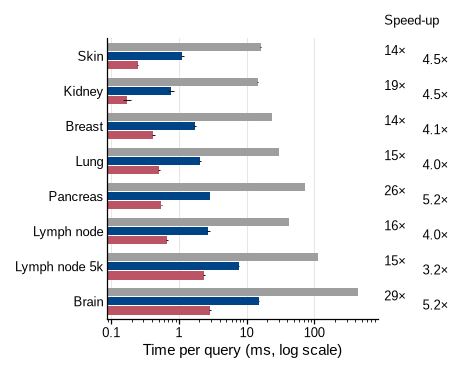

<Figure size 732.283x41.3386 with 0 Axes>

In [2]:
TIME_HANDLES = [Patch(color=WHOLE, label="Whole-matrix scan"), Patch(color=NAIVE, label="Spindle-naive"),
                Patch(color=SPINDLE, label="Spindle")]


def panel_a(fig):
    W, H_ = ps.size_mm(fig)
    right = 15.0
    ax = ps.axes(fig, left=17.0, right=right, bottom=ROW_BOTTOM, top=ROW_TOP)
    t = timing
    bh = 0.26
    for i, k in enumerate(KEYS):
        r = t.loc[k]
        for off, col, c in ((-bh, "whole_ms", WHOLE), (0, "naive_ms", NAIVE), (bh, "spindle_ms", SPINDLE)):
            ax.barh(i + off, r[col], height=bh * 0.92, color=c, lw=0, zorder=2)
            ax.errorbar(r[col], i + off, xerr=r[f"{col}_sd"], fmt="none", ecolor=ps.INK, elinewidth=0.5, zorder=3)
    ax.set_xscale("log")
    ps.plain_log(ax, "x", subs=(1.0,))
    ps.log_grid(ax, "x")
    ax.set_xlim(min(t.spindle_ms.min(), t.naive_ms.min()) / 2, t.whole_ms.max() * 2)
    rows_axis(ax, True)
    ax.set_xlabel("Time per query (ms, log scale)")
    # speed-ups: whole-matrix scan / Spindle-naive (left), Spindle-naive / Spindle (right)
    tr = blended_transform_factory(fig.transSubfigure if hasattr(fig, "transSubfigure") else fig.transFigure,
                                   ax.transData)
    x0 = (W - right + 1.0) / W
    x1 = (W - right + 7.5) / W
    for i, k in enumerate(KEYS):
        r = t.loc[k]
        ax.text(x0, i - bh / 2, f"{r.speedup_naive_vs_whole:.0f}×", transform=tr, fontsize=ps.TICK_PT, va="center")
        ax.text(x1, i + bh / 2, f"{r.speedup_spindle_vs_naive:.1f}×", transform=tr, fontsize=ps.TICK_PT, va="center")
    fig.text(x0, 1 - 0.5 / H_, "Speed-up", fontsize=ps.TICK_PT, va="top")


def panel_legend(fig):
    fig.legend(handles=TIME_HANDLES, ncol=3, loc="upper center", columnspacing=1.2)


fig = ps.panel(W_A, H)
panel_a(fig)
ps.save_panel(fig, FIG, "A")
fig = ps.panel(W_A + W_B, LEG_H - 1.0)
panel_legend(fig)
ps.save_panel(fig, FIG, "legend")

## B · RDE and NNR of Spindle at 5 % of N

figures/fig3_whole_tile/panels/B.pdf/.png: 46 x 62 mm, 0.0 / 0.1 MB


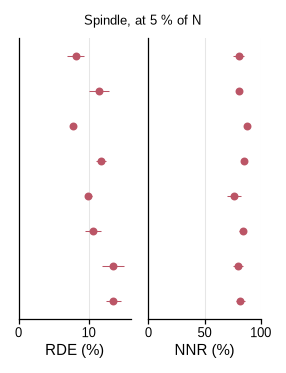

In [3]:
def panel_b(fig):
    W, _ = ps.size_mm(fig)
    t = nx[nx.g == G].set_index("key")
    specs = [("NX5", "RDE (%)", (0, 16)), ("overlap5", "NNR (%)", (0, 100))]
    w = (W - 2.0) / 2
    for j, (col, xlabel, xlim) in enumerate(specs):
        ax = ps.axes(fig, left=2.0 + j * w, right=W - 2.0 - (j + 1) * w + 3.0, bottom=ROW_BOTTOM, top=ROW_TOP)
        for i, k in enumerate(KEYS):
            r = t.loc[k]
            ax.errorbar(100 * r[col], i, xerr=100 * r[f"{col}_sd"], fmt="o", ms=2.8, color=SPINDLE, elinewidth=0.5,
                        zorder=3)
        rows_axis(ax, False)
        ax.set_xlim(*xlim)
        ax.grid(True, axis="x", color="#E6E6E6", linewidth=0.5, zorder=0)
        ax.set_axisbelow(True)
        ax.set_xlabel(xlabel)
    fig.text(0.5, 1 - 0.5 / H, "Spindle, at 5 % of N", ha="center", va="top", fontsize=ps.TICK_PT)


fig = ps.panel(W_B, H)
panel_b(fig)
ps.save_panel(fig, FIG, "B")

## C · The typical breast query, with the budget

breast typical query: N = 1840, returned 484, budget c = 92, d_c = 0.749
figures/fig3_whole_tile/panels/C.pdf/.png: 56 x 62 mm, 0.0 / 0.2 MB


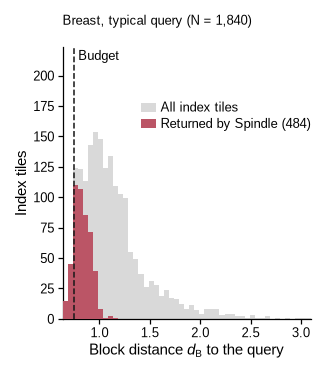

In [4]:
def panel_c(fig):
    z = np.load(RES / "band" / "breast_cancer.npz")
    d, found = z["d"], z["found"]
    c = rt.c5(len(d))
    budget = np.sort(d)[c - 1]
    print(f"breast typical query: N = {len(d)}, returned {len(found)}, budget c = {c}, d_c = {budget:.3f}")
    ax = ps.axes(fig, left=12.0, right=2.0, bottom=ROW_BOTTOM, top=ROW_TOP + 1.5)
    bins = np.linspace(d.min(), np.quantile(d, 0.995), 50)
    n_all, _, _ = ax.hist(d, bins=bins, color=ps.LIGHT, lw=0, zorder=2, label="All index tiles")
    ax.hist(d[found], bins=bins, color=SPINDLE, lw=0, zorder=3, label=f"Returned by Spindle ({len(found)})")
    ax.axvline(budget, ls="--", lw=0.75, color=ps.INK, zorder=4)
    ax.set_ylim(0, 1.45 * n_all.max())
    ax.text(budget, 0.99, " Budget", transform=ax.get_xaxis_transform(), ha="left", va="top", fontsize=ps.TICK_PT)
    ax.set_xlabel(r"Block distance $d_{\mathcal{B}}$ to the query")
    ax.set_ylabel("Index tiles")
    ax.set_xlim(bins[0], bins[-1])
    ax.legend(loc="upper right", bbox_to_anchor=(1.0, 0.8))
    W, H_ = ps.size_mm(fig)
    fig.text(0.5, 1 - 0.5 / H_, f"Breast, typical query (N = {len(d):,})", ha="center",
             va="top", fontsize=ps.TICK_PT)


fig = ps.panel(W_C, H)
panel_c(fig)
ps.save_panel(fig, FIG, "C")

## Full figure

breast typical query: N = 1840, returned 484, budget c = 92, d_c = 0.749
figures/fig3_whole_tile/fig3_whole_tile.pdf/.png: 180 x 70 mm, 0.0 / 0.6 MB


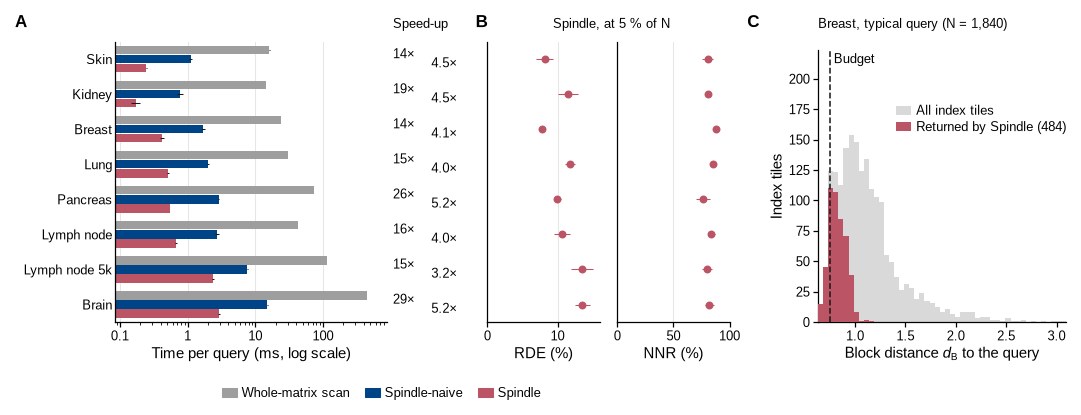

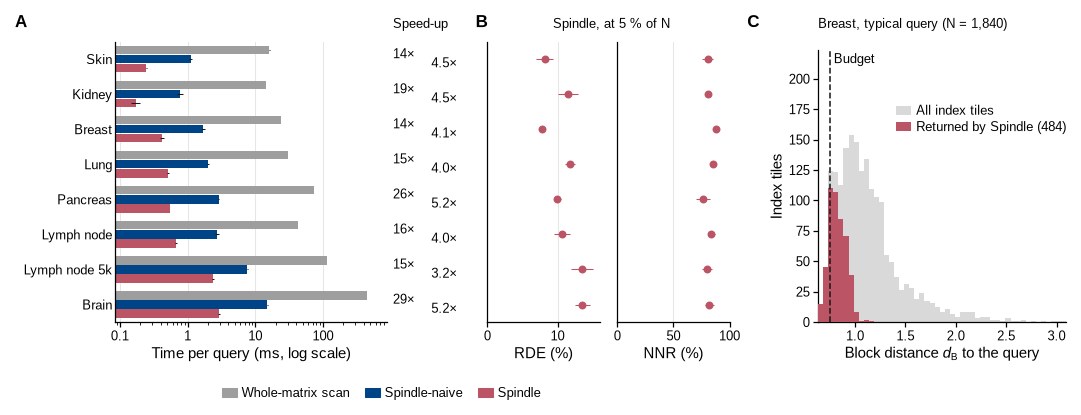

In [5]:
page = ps.page(180, H + LEG_H)
panel_a(ps.place(page, "A", 0, 0, W_A, H))
panel_b(ps.place(page, "B", W_A, 0, W_B, H))
panel_c(ps.place(page, "C", W_A + W_B, 0, W_C, H))
panel_legend(ps.place(page, None, 0, H + 1.0, W_A + W_B, LEG_H - 1.0))
ps.save_figure(page, FIG)
page